In [1]:
import matplotlib.pyplot as plt
import numpy as np

from hnn_core import new_calcium_model, simulate_dipole, jones_2009_model

from hnn_core.params import compare_dictionaries

from hnn_core.viz import plot_cell_morphology

# import pandas as pd
from scipy import signal
from plot_utils import fig_conductances, fig_compartments
from matplotlib.gridspec import GridSpec
import os
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

pathfig = '/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/new_hnn_model_connected/'
#os.mkdir(pathfig)

# colormap settings
from matplotlib import colormaps
import matplotlib.patches as mpatches

cmap = colormaps['Set2']

cell_types = ['L2_inhibitory', 'L2_pyramidal', 'L5_inhibitory', 'L5_pyramidal']
cell_type_colors = {'L2_basket': cmap.colors[0], 'L2_pyramidal': cmap.colors[1], 
               'L5_basket': cmap.colors[3], 'L5_pyramidal': cmap.colors[4]}


# Hack a colormap

from scipy.interpolate import RectBivariateSpline
from hnn_core.extracellular import _get_laminar_z_coords, calculate_csd2d
from hnn_core.viz import plot_laminar_csd

In [2]:
net = jones_2009_model()#new_calcium_model()


net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

net.add_tonic_bias(cell_type='L5_pyramidal',section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')


Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Loading custom mechanism files from /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/local_hnn/hnn_core/mod/arm64/.libs/libnrnmech.so
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


In [3]:
# clamp signal for plotting
timevec = net.cell_response.times

clamp = np.zeros_like(timevec) 

for bias in net.external_biases:
    for cell_type in net.external_biases[bias]:
        t0 = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['t0']))
        tstop = np.argmin(np.abs(timevec - net.external_biases[bias][cell_type]['tstop']))

        clamp[t0:tstop] = net.external_biases[bias][cell_type]['amplitude']

In [4]:
# get calcium and membrane potential
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]

l5_first = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0][0]]
vltg = net.cell_response.vsec[0][int(l5_first)]
ca = net.cell_response.ca[0][int(l5_first)]

l5_gids = gids[np.where(((gids > 169).astype(float) + (gids <=270).astype(float)) == 2)[0]]
l5_unique_gids = np.array([])
for l5 in l5_gids:
    if ~np.isin(l5,l5_unique_gids):
        l5_unique_gids = np.append(l5_unique_gids, l5)

ca_l5_tuft = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
ca_l5_apcl2 = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
vltg_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))
ca_l5_soma = np.zeros((l5_unique_gids.shape[0], len(net.cell_response.times)))

for i, g in enumerate(l5_unique_gids.astype(int)):
    ca_l5_tuft[i] = net.cell_response.ca[0][g]['apical_tuft']
    ca_l5_apcl2[i] = net.cell_response.ca[0][g]['apical_2']
    ca_l5_soma[i] = net.cell_response.ca[0][g]['apical_2']
    vltg_l5_soma[i] = net.cell_response.vsec[0][g]['soma']

In [5]:
# smooth dipole
window_len, scaling_factor = 20, 3000
dpl[0].scale(scaling_factor).smooth(window_len)

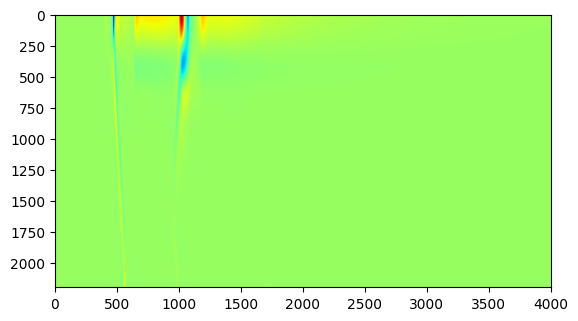

In [6]:
# CSD colormap

contact_labels, delta = _get_laminar_z_coords(net.rec_arrays['probe1'][0].positions)

csd_data = calculate_csd2d(net.rec_arrays['probe1'][0].voltages[0], delta=1)
interp_data = RectBivariateSpline(net.cell_response.times, contact_labels, csd_data.T)
# increase number of contacts
new_depths = np.linspace(contact_labels[0], contact_labels[-1],
                            contact_labels[-1] - contact_labels[0])
# interpolate
csd_data = interp_data(net.cell_response.times, new_depths).T

im_new = plt.imshow(csd_data,aspect=1, cmap='jet')

In [7]:
def assign_color(gid):
    for cell_type, gid_range in net.gid_ranges.items():
        if cell_type in list(cell_type_colors.keys()):
            if gid in gid_range:
                return cell_type_colors[cell_type]

/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_60113/216879263.py:57: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1600x600 with 10 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im_new, ax= ax[3], orientation='horizontal', shrink=0.5).set_label(r'$CSD (uV/um^{2})$')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_60113/216879263.py:65: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[3].set_xticklabels(np.arange(-75, 100, 25))


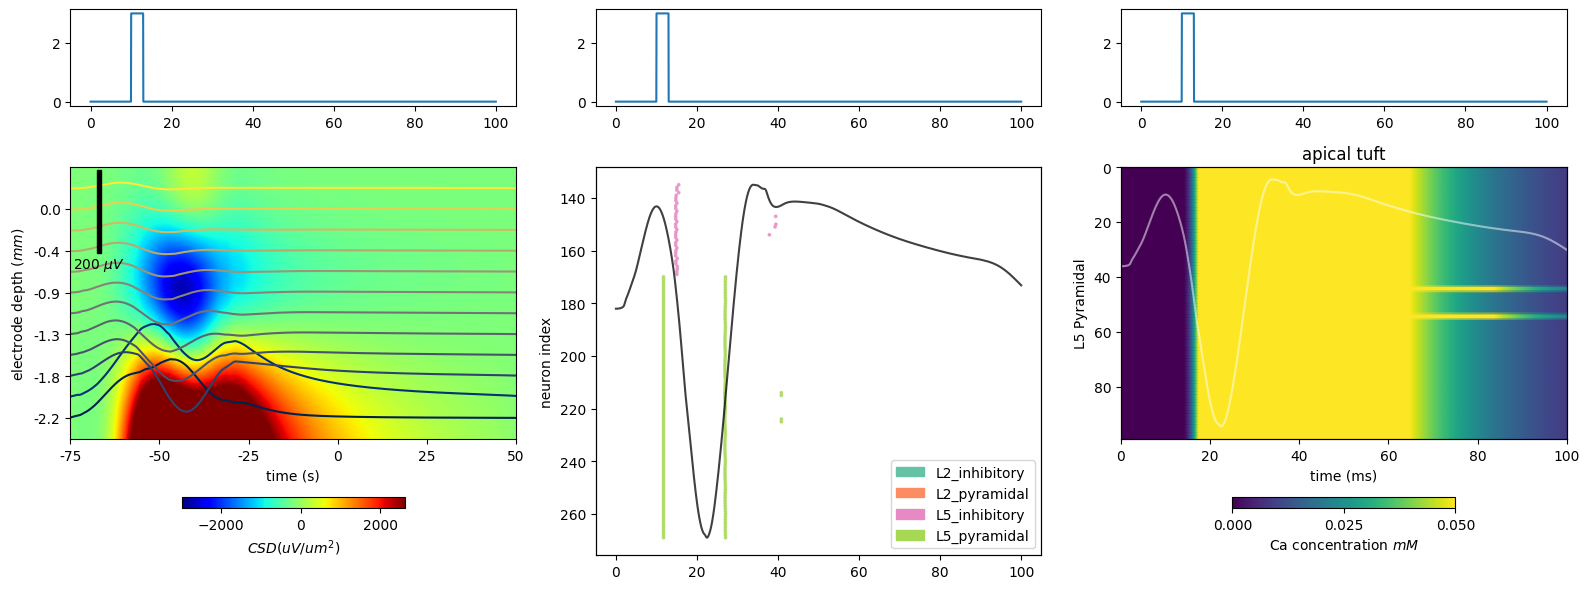

In [8]:

fig, ax = plt.subplots(2,3, figsize=(16, 6), height_ratios=[0.25, 1])

ax = ax.ravel()

for i,a in enumerate(ax[:3]):
    a.plot(timevec, clamp)

colors = [assign_color(gid) for gid in gids]

ax[4].scatter(times, gids, s=3, alpha=0.74, c=colors)
ax[4].set_ylabel('neuron index')
ax[4].invert_yaxis()
ax1tw = ax[4].twinx()
ax1tw.plot(timevec,dpl[0].data['agg'],color='k', alpha=0.75)

ax1tw.set_yticks([])
# Create custom legend handles
legend_handles = [mpatches.Patch(color=color, label=group) for group, color in zip(cell_types,cell_type_colors.values())]

# Add the legend
ax[4].legend(handles=legend_handles,loc='lower right')

# calcium concentration

im = ax[5].pcolormesh(timevec,np.arange(len(l5_unique_gids)),ca_l5_tuft, shading='gouraud',vmin=0, vmax=0.05)
ax[5].invert_yaxis()
ax[5].set_title('apical tuft')
ax[5].set_xlabel('time (ms)')

# Create a divider for existing axes instance
# divider = make_axes_locatable(ax[4])

# # Append axes to the bottom of the main axes, with 5% height
# cax = divider.append_axes("bottom", size="5%", pad=0.5)
cb = plt.colorbar(im, ax= ax[5], orientation='horizontal', shrink=0.5)
cb.set_ticks(np.arange(0,0.06,0.025))


cb.set_label('Ca concentration $mM$')
ax2 = ax[5].twinx()
ax2.plot(timevec,dpl[0].data['agg'], color=(1,1,1), alpha=0.5)

#ax[6].set_ylabel('L5 Pyramidal (active only')
ax[5].set_xlabel('time (ms)')
ax2.set_yticks([])
#ax2.set_ylabel('dipole')
ax[5].set_ylabel('L5 Pyramidal')

# LFP & CSD


net.rec_arrays['probe1'][0].smooth(window_len=window_len).plot_lfp(ax=ax[3], show=False)

net.rec_arrays['probe1'][0].smooth(window_len=window_len).plot_csd(ax=ax[3], show=False, vmin=-0.006, vmax=.006, colorbar=False, sink='b')


cb = plt.colorbar(im_new, ax= ax[3], orientation='horizontal', shrink=0.5).set_label(r'$CSD (uV/um^{2})$')
#cb.set_ticks(np.arange(0,0.06,0.025))

ticks = ax[3].get_yticks()
new_ticks = ticks[0:len(ticks):2]
ax[3].set_yticks(new_ticks)
ax[3].set_yticklabels(np.round(np.linspace((contact_labels[0] - contact_labels[-1])/1000,0,len(new_ticks)),1))
ax[3].set_ylabel('electrode depth ($mm$)')
ax[3].set_xticklabels(np.arange(-75, 100, 25))

fig.tight_layout()
fig.savefig('jones_2009_tonic_l5_soma.png')

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_60113/2422952915.py:53: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 1200x600 with 6 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(im_new, ax= ax[2], orientation='horizontal', shrink=0.5).set_label(r'$CSD (uV/um^{2})$')
/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_60113/2422952915.py:61: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax[2].set_xticklabels(np.arange(-75, 100, 25))


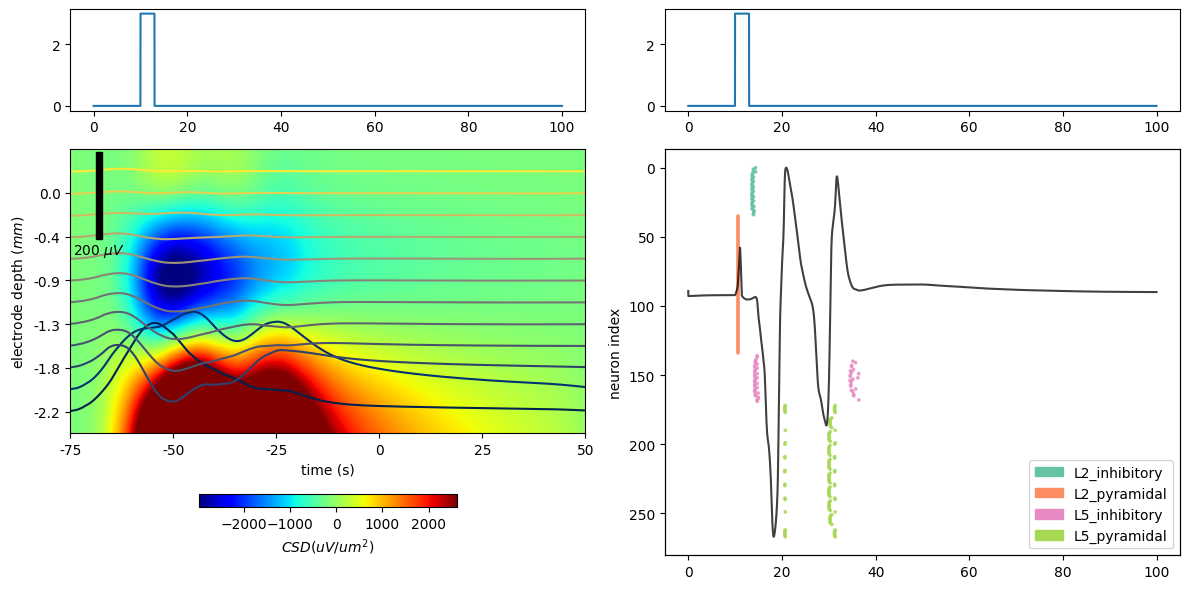

In [9]:
del net

# stimulate L2/3 pyramidal
net = jones_2009_model()#new_calcium_model()

net.set_cell_positions(inplane_distance=30.)

depths = list(list(range(-100,2200,200)))
electrode_pos = [(135, 135, dep) for dep in depths]

net.add_electrode_array('probe1', electrode_pos)

ampl = 3.
t0 = 10

net.add_tonic_bias(cell_type='L2_pyramidal',section='soma',bias_name='tonic_soma',amplitude=ampl,t0=t0,tstop=t0+3)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

# spiking
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]

fig, ax = plt.subplots(2,2, figsize=(12, 6), height_ratios=[0.25, 1])

ax = ax.ravel()

for i,a in enumerate(ax[:2]):
    a.plot(timevec, clamp)

colors = [assign_color(gid) for gid in gids]

ax[3].scatter(times, gids, s=3, alpha=0.74, c=colors)
ax[3].set_ylabel('neuron index')
ax[3].invert_yaxis()
ax1tw = ax[3].twinx()
ax1tw.plot(timevec,dpl[0].data['agg'],color='k', alpha=0.75)

ax1tw.set_yticks([])
# Create custom legend handles
legend_handles = [mpatches.Patch(color=color, label=group) for group, color in zip(cell_types,cell_type_colors.values())]

# Add the legend
ax[3].legend(handles=legend_handles,loc='lower right')


net.rec_arrays['probe1'][0].smooth(window_len=window_len).plot_lfp(ax=ax[2], show=False)

net.rec_arrays['probe1'][0].smooth(window_len=window_len).plot_csd(ax=ax[2], show=False, vmin=-0.006, vmax=.006, colorbar=False, sink='b')


cb = plt.colorbar(im_new, ax= ax[2], orientation='horizontal', shrink=0.5).set_label(r'$CSD (uV/um^{2})$')
#cb.set_ticks(np.arange(0,0.06,0.025))

ticks = ax[2].get_yticks()
new_ticks = ticks[0:len(ticks):2]
ax[2].set_yticks(new_ticks)
ax[2].set_yticklabels(np.round(np.linspace((contact_labels[0] - contact_labels[-1])/1000,0,len(new_ticks)),1))
ax[2].set_ylabel('electrode depth ($mm$)')
ax[2].set_xticklabels(np.arange(-75, 100, 25))

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_2009_tonic_l2_soma.png'))

In [10]:
I = np.array(net.cell_response.spike_gids[0]) <270
gids = np.array(net.cell_response.spike_gids).reshape(-1,)[I]
times = np.array(net.cell_response.spike_times).reshape(-1,)[I]

In [11]:
net.connectivity

[L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0005; delay: 1.0; lamtha: 3.0
  ,
 L2_pyramidal -> L2_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0005; delay: 1.0; lamtha: 3.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'nmda'
 weight: 0.0005; delay: 1.0; lamtha: 3.0
  ,
 L5_pyramidal -> L5_pyramidal
 cell counts: 100 srcs, 100 targets
 connection probability: 1.0 
 loc: 'proximal'; receptor: 'ampa'
 weight: 0.0005; delay: 1.0; lamtha: 3.0
  ,
 L2_basket -> L2_pyramidal
 cell counts: 35 srcs, 100 targets
 connection probability: 1.0 
 loc: 'soma'; receptor: 'gabaa'
 weight: 0.05; delay: 1.0; lamtha: 50.0
  ,
 L2_basket -> L2_pyramidal
 cell counts: 35 srcs, 100 targets
 connection probability: 1.0 
 loc: 'soma'; receptor: 'gabab'
 wei

In [12]:
net = jones_2009_model()

weights_ampa_p1 = {'L2_basket': 0.08831, 'L2_pyramidal': 0.01525,
                   'L5_basket': 0.19934, 'L5_pyramidal': 0.00865}
synaptic_delays_prox = {'L2_basket': 0.1, 'L2_pyramidal': 0.1,
                        'L5_basket': 1., 'L5_pyramidal': 1.}
# all NMDA weights are zero; pass None explicitly
net.add_evoked_drive(
    'evprox', mu=26.61, sigma=2.47, numspikes=1, weights_ampa=weights_ampa_p1,
    weights_nmda=None, location='proximal',
    synaptic_delays=synaptic_delays_prox, event_seed=544)

dpl = simulate_dipole(net, tstop=100, n_trials=1,record_vsec='all',record_isec='all',record_ca='all')

bins = np.linspace(timevec[0],timevec[-1],50)



Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Trial 1: 80.0 ms...
Trial 1: 90.0 ms...


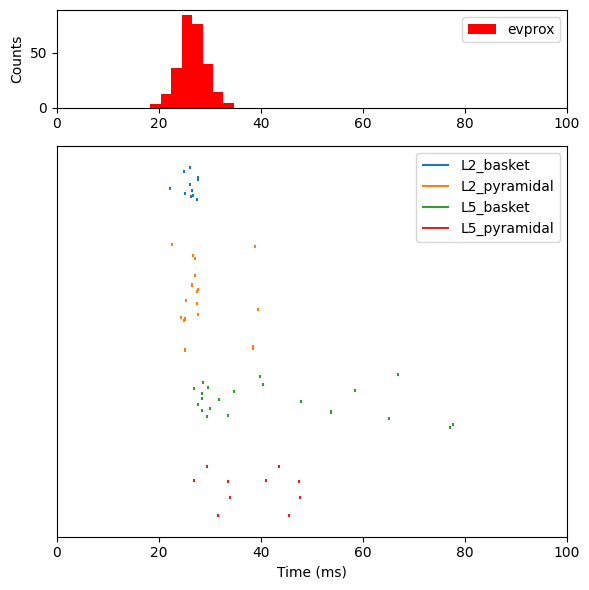

In [13]:
fig, ax = plt.subplots(2,1, figsize=(6, 6), height_ratios=[0.25, 1])

net.cell_response.plot_spikes_hist(ax=ax[0], spike_types=['evprox'], show=False)
net.cell_response.plot_spikes_raster(ax=ax[1], show=False)

fig.tight_layout()
fig.savefig(os.path.join(pathfig, 'jones_2009_proximal_drive.png'))